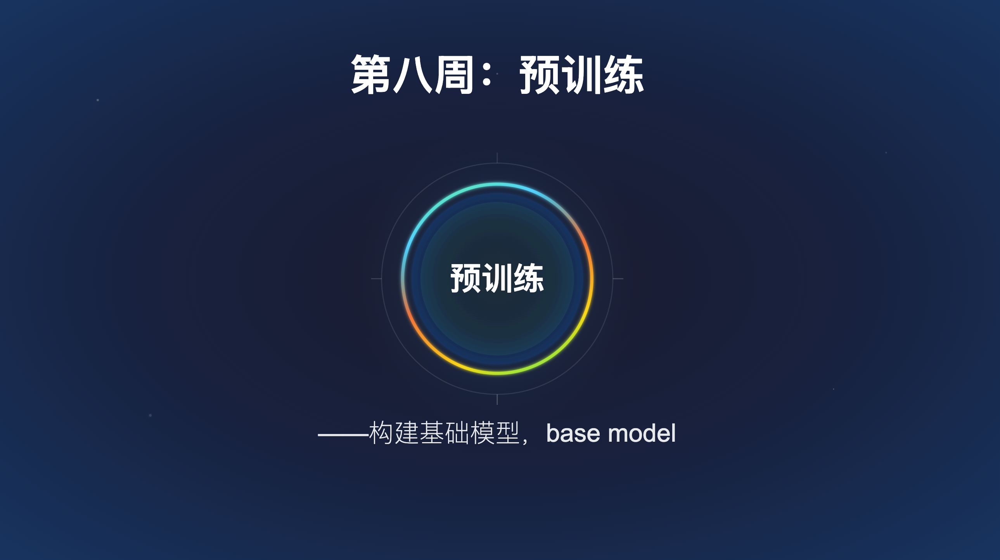

# 一、大模型技术全栈概览

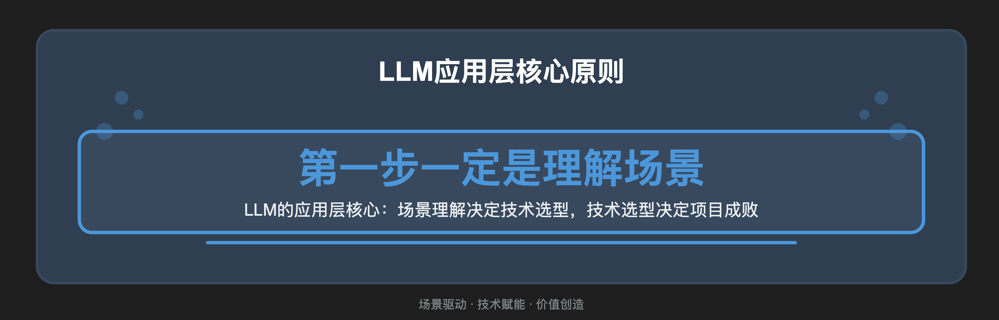

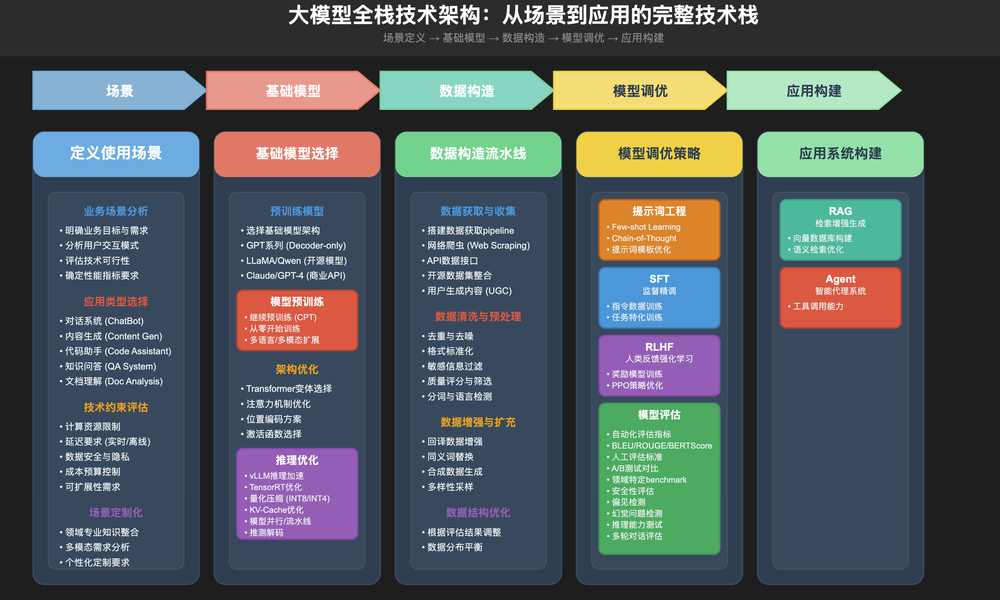

# 二、预训练的原理

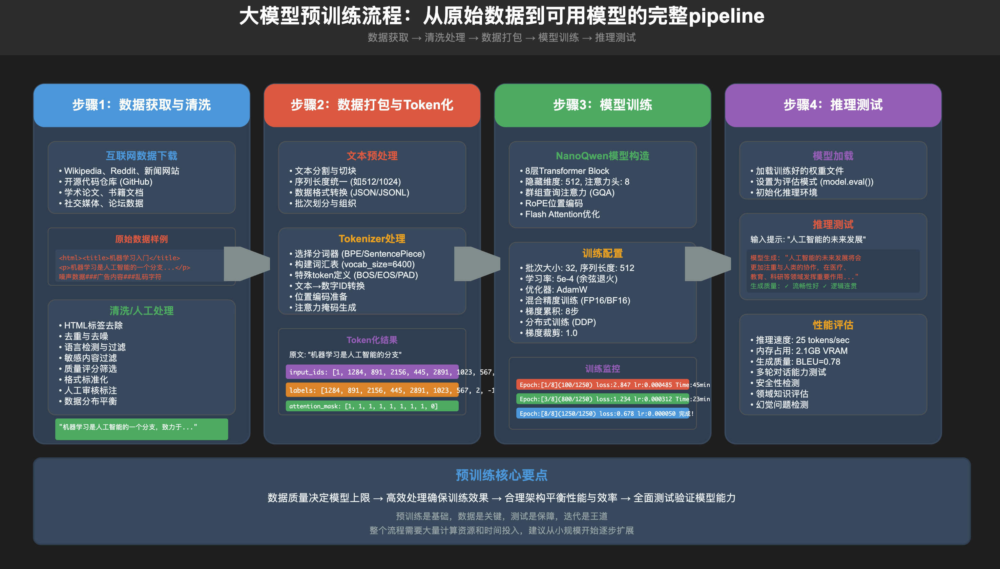

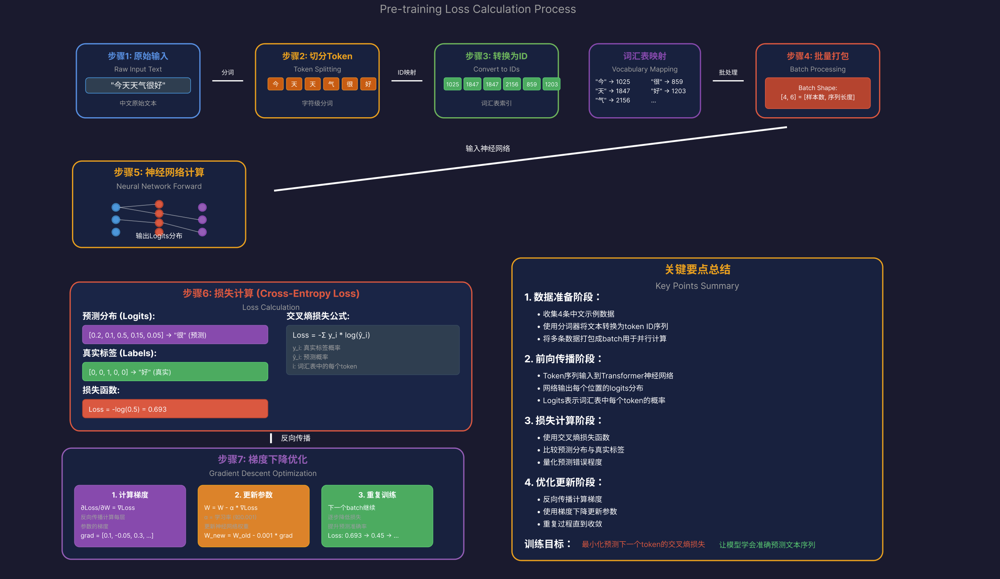

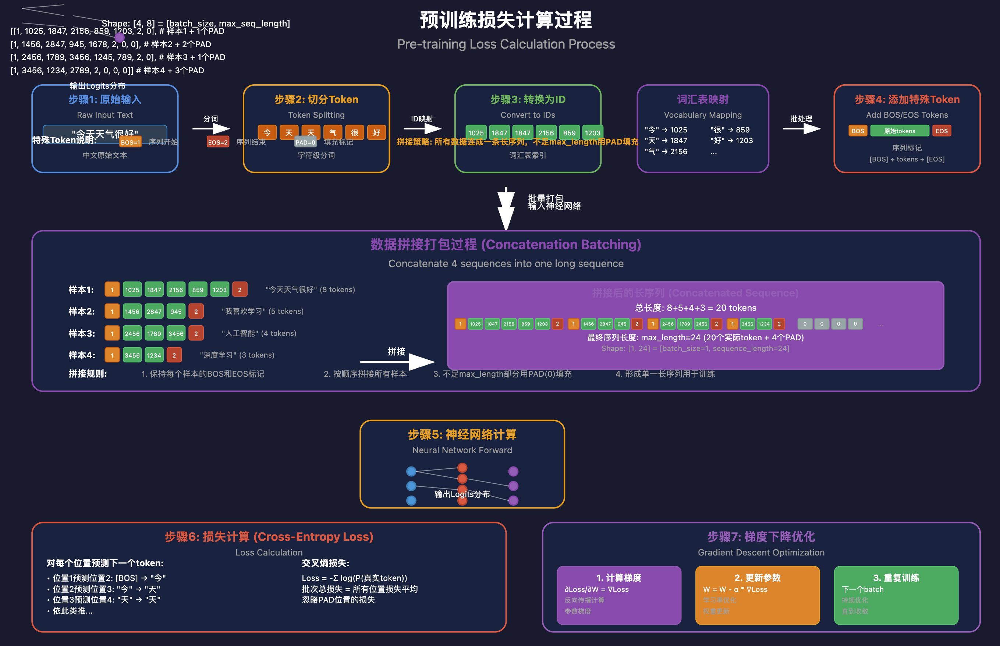

# 三、预训练的数据构造

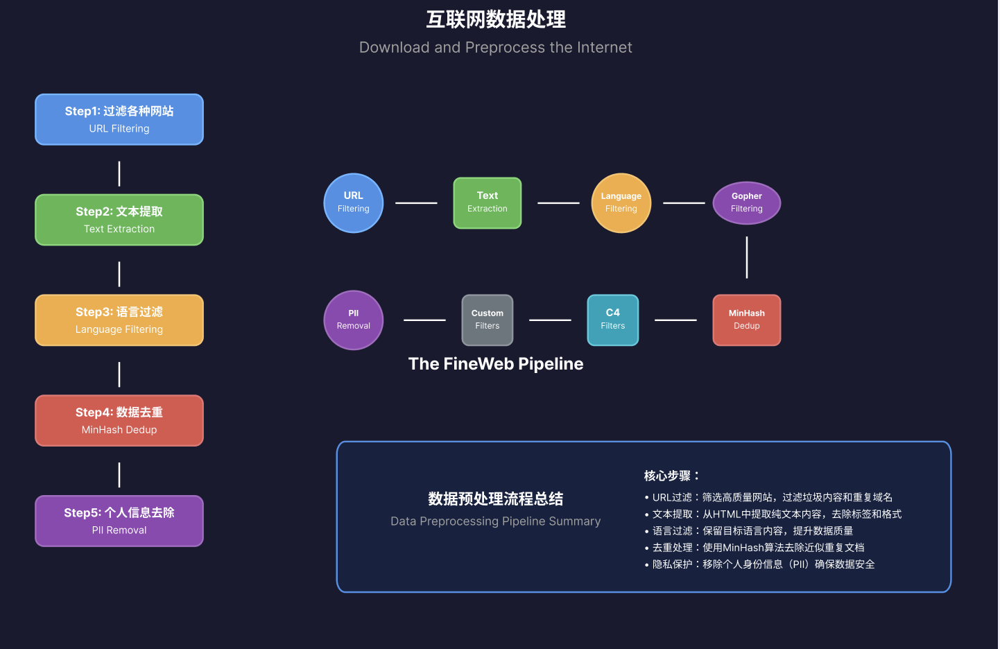

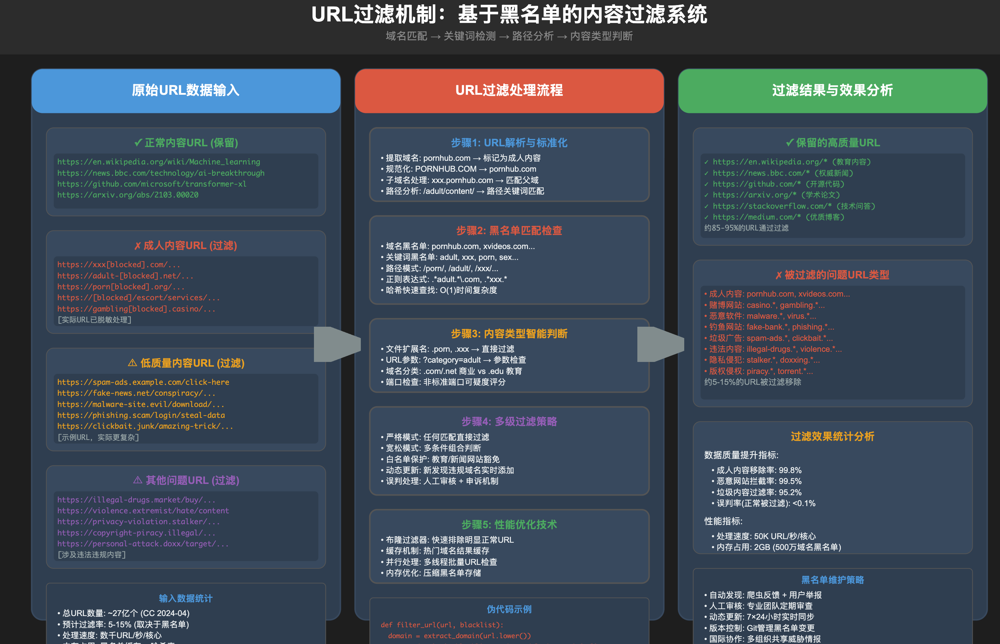

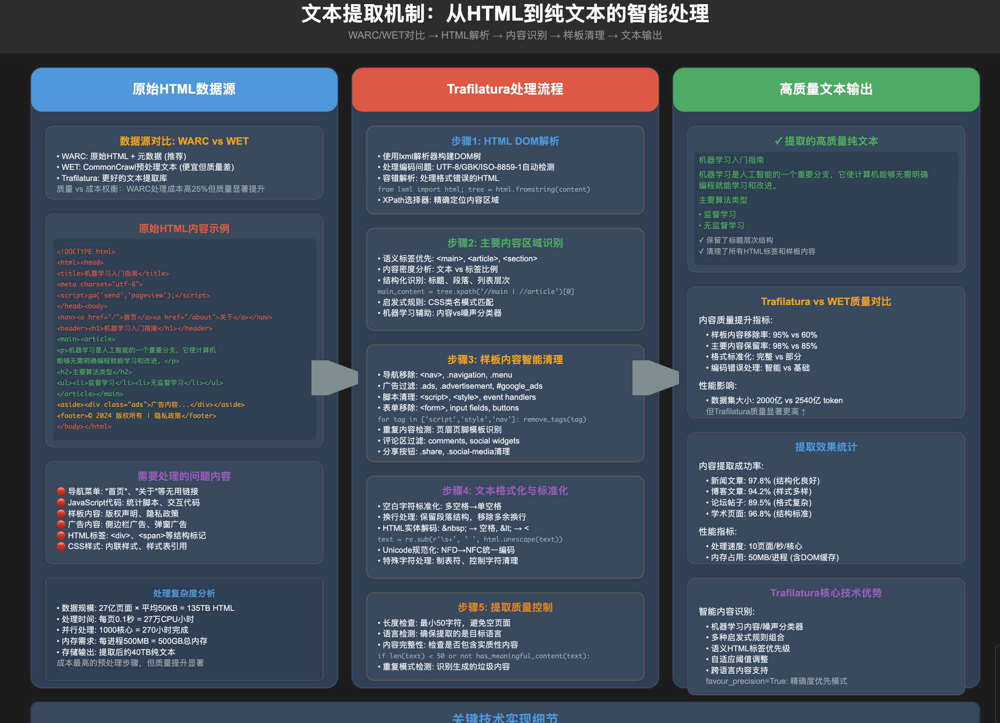

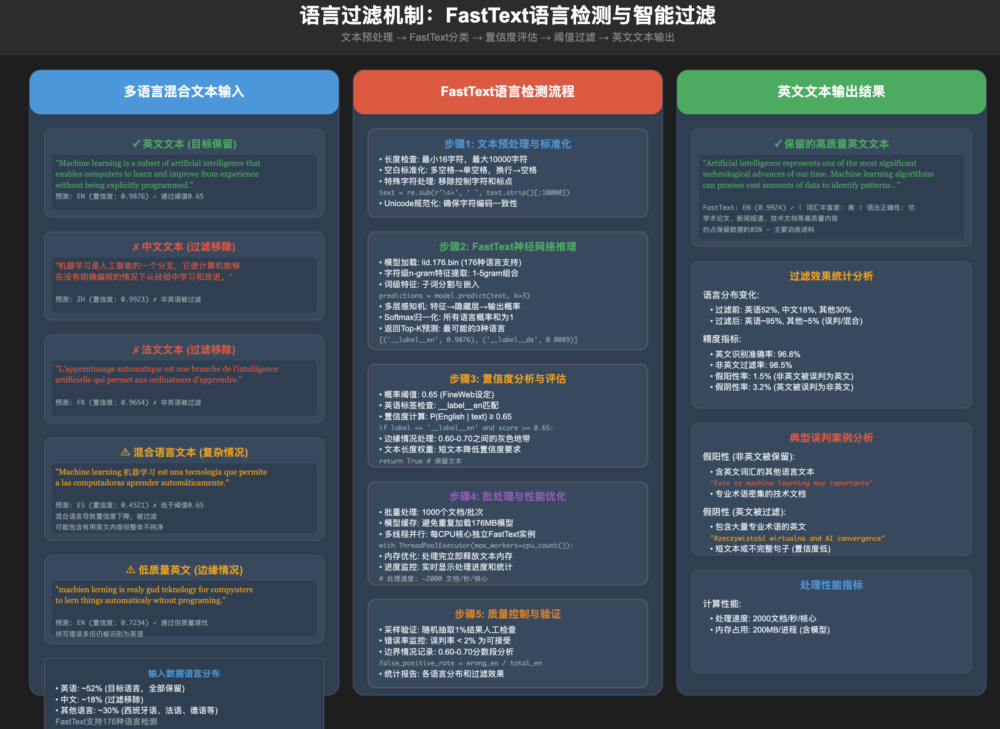

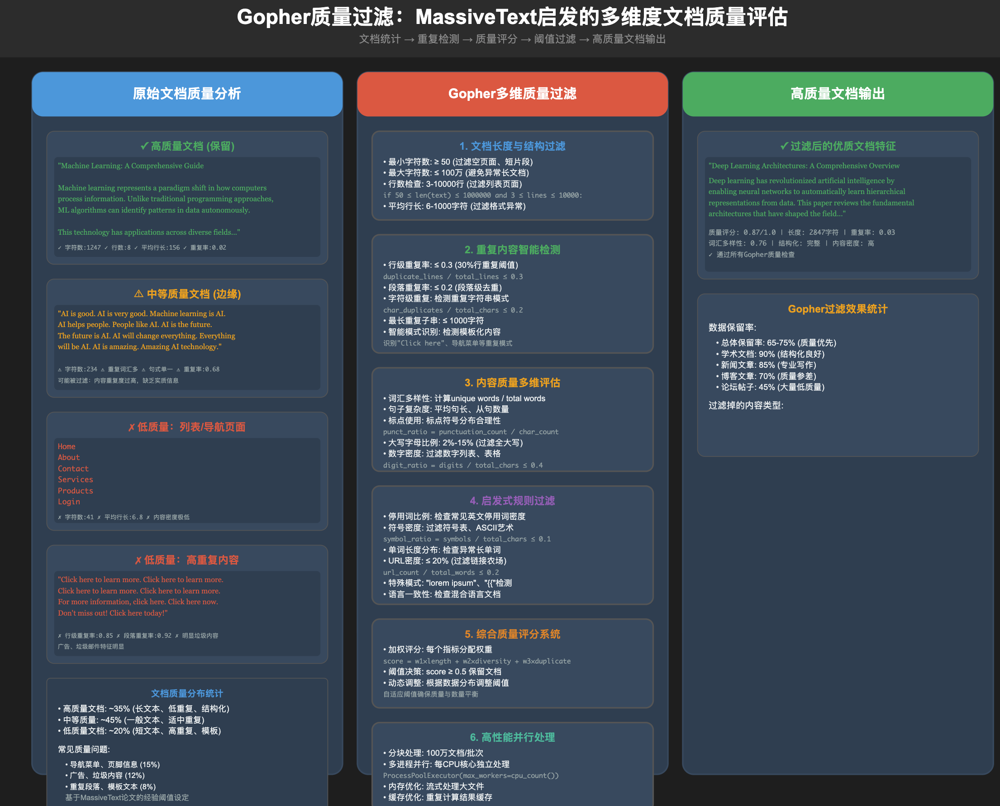

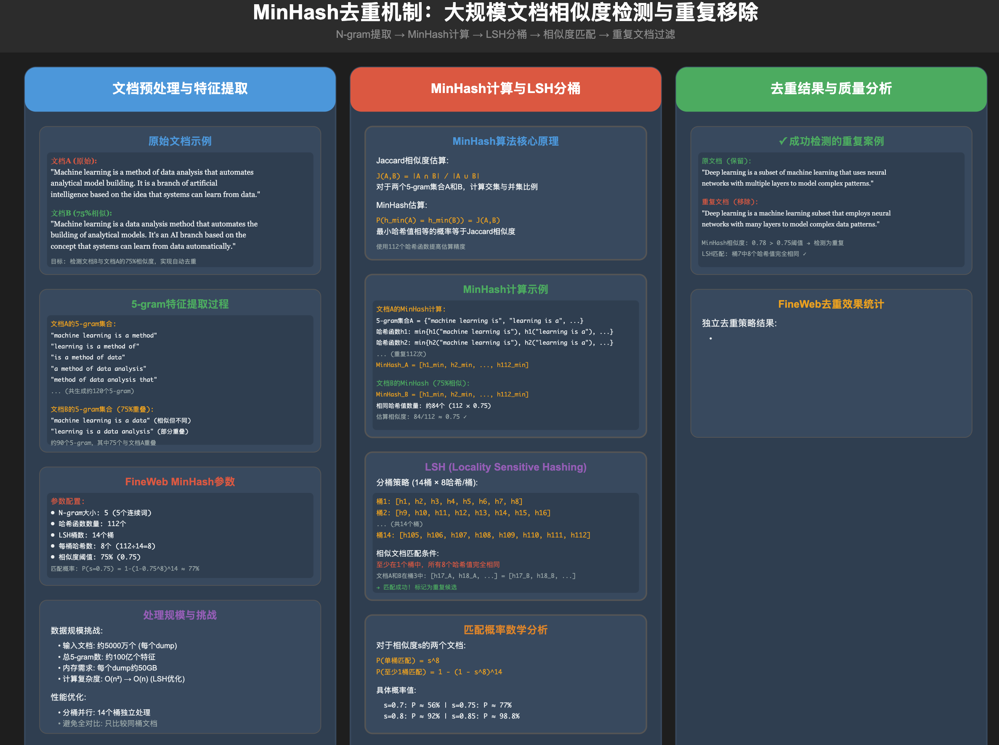

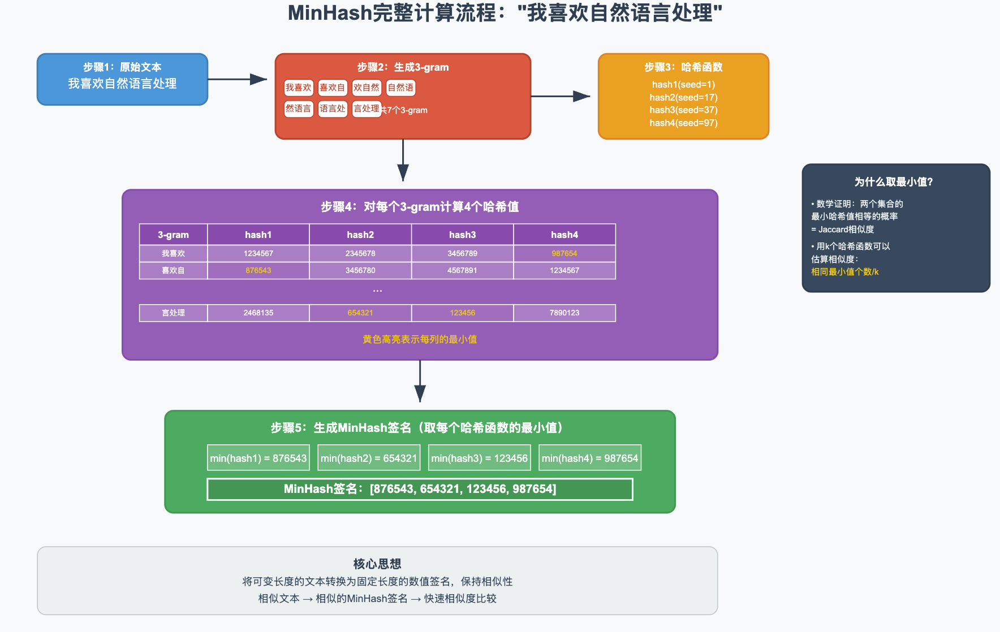

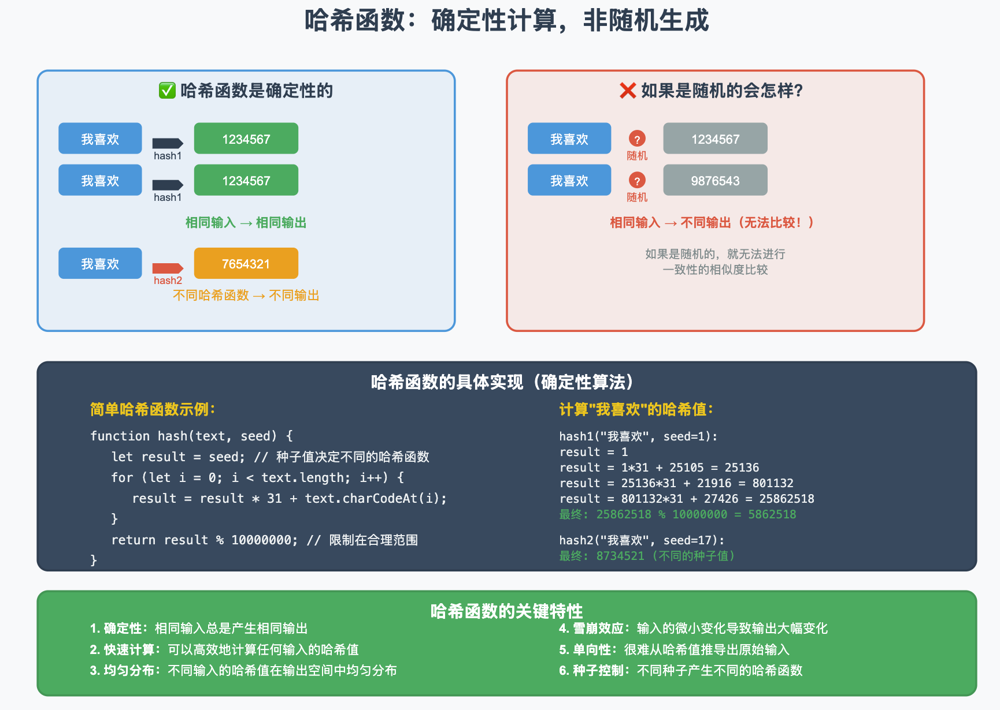

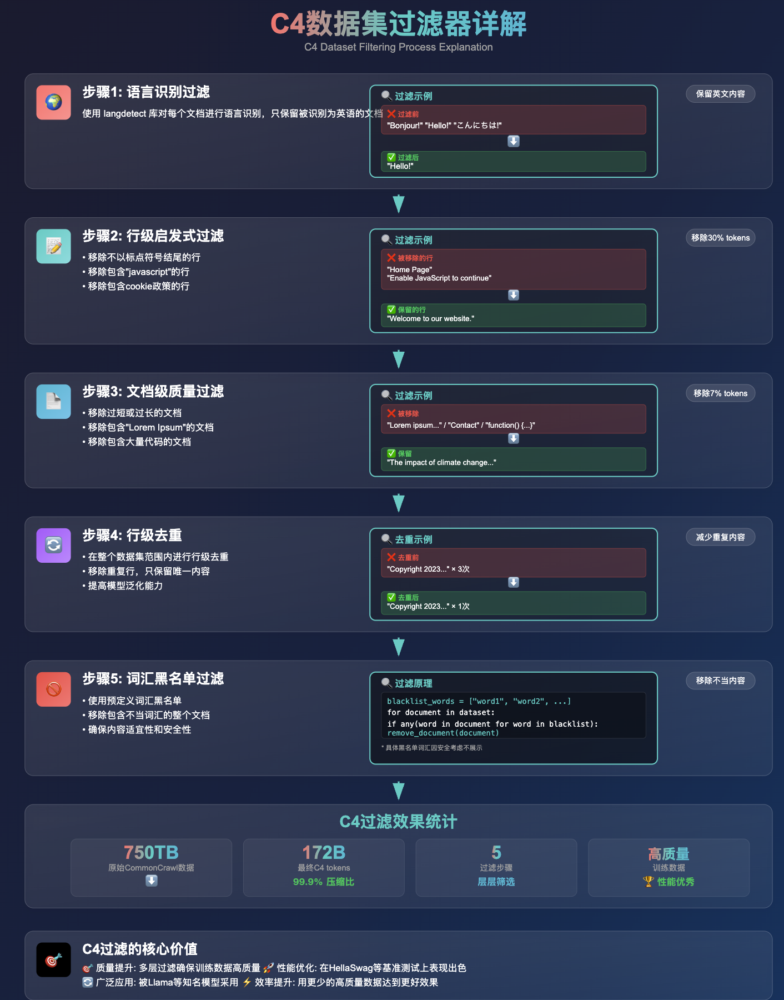



### 🛡️ PII 检测（Identification）

识别文本中的 **个人可识别信息（PII）** 是数据脱敏和隐私保护的重要第一步。

---

#### 🧰 方法一：基于规则的方法（Rule-based）

##### ✅ 原理：

使用 **正则表达式（Regex）** 等预定义的模式匹配结构化或格式固定的 PII。

##### 🧪 例子：

| PII 类型  | 正则表达式示例                                          |
| ------- | ------------------------------------------------ |
| 📧 邮箱   | `[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}` |
| 📱 电话号码 | `\d{3}-\d{8}` 或 `\d{4}-\d{7}` 或 `1[3-9]\d{9}`    |
| 🆔 身份证号 | `\d{17}[\dXx]`                                   |

##### ✅ 优缺点：

| 优点          | 缺点                   |
| ----------- | -------------------- |
| 快速、准确、易实现   | 无法处理格式不固定的 PII       |
| 对结构化数据识别效果好 | 不理解上下文，漏检如“我叫李华”这类表达 |

---

#### 🤖 方法二：基于模型的方法（Model-based）

##### ✅ 原理：

使用 **命名实体识别（NER）模型** 来识别文本中的实体，如 `PERSON`, `LOCATION`, `ORGANIZATION` 等。

##### 🤖 常用模型：

* spaCy（预训练 NER 模型）
* BERT + CRF（上下文理解更强）
* 自定义微调模型（适用于特定行业）

##### ✅ 优缺点：

| 优点              | 缺点                |
| --------------- | ----------------- |
| 能识别上下文相关实体，格式灵活 | 训练和推理成本高，可能有误报或漏报 |
| 能识别人名、地名、组织等    | 依赖数据质量和模型鲁棒性      |

---

#### 🔀 实践推荐：规则 + 模型联合 + 大模型

多数系统会采用 **规则引擎 + 模型识别** 的混合方案：

* 规则先行，快速筛选明确格式的 PII；
* 模型补充识别不规则、语义相关的 PII。

---

#### 📄 示例：PII 检测演示

##### 原始文本：

```
你好，我是张伟，我的项目遇到问题了。我的邮箱是 zhangwei@email.com，电话是 138-1234-5678。你可以随时联系我，我住在阳光小区A栋501。
```

##### 检测结果：

| PII 类型  | 文本片段                 |
| ------- | -------------------- |
| 👤 人名   | “张伟”                 |
| 📧 邮箱   | `zhangwei@email.com` |
| 📱 电话号码 | `138-1234-5678`      |
| 🏠 地址   | “阳光小区A栋501”          |

---

#### ✅ 总结

| 方法   | 是否依赖格式 | 是否理解语义 | 检测能力  |
| ---- | ------ | ------ | ----- |
| 规则法  | ✅ 是    | ❌ 否    | ⭐⭐⭐   |
| 模型法  | ❌ 否    | ✅ 是    | ⭐⭐⭐⭐  |
| 混合策略 | ❌ 否    | ✅ 是    | ⭐⭐⭐⭐⭐ |


# 四、预训练实战

##  预训练环境搭建与运行指南

### ✅ 创建 Conda 环境

```bash
conda create -n pretrain python=3.10
source ~/.bashrc
conda activate pretrain
````

### 📦 安装依赖（使用清华源）

```bash
python -m pip install -r requirements.txt -i https://pypi.tuna.tsinghua.edu.cn/simple
```

### ▶️ 启动训练

```bash
cd trainer
python train_pretrain.py
```

### 🧪 模型评估（测试）


```bash
python eval_model.py  
```


### 如果要看训练数据
```bash
cd dataset
head -10 pretrain_hq.json
```


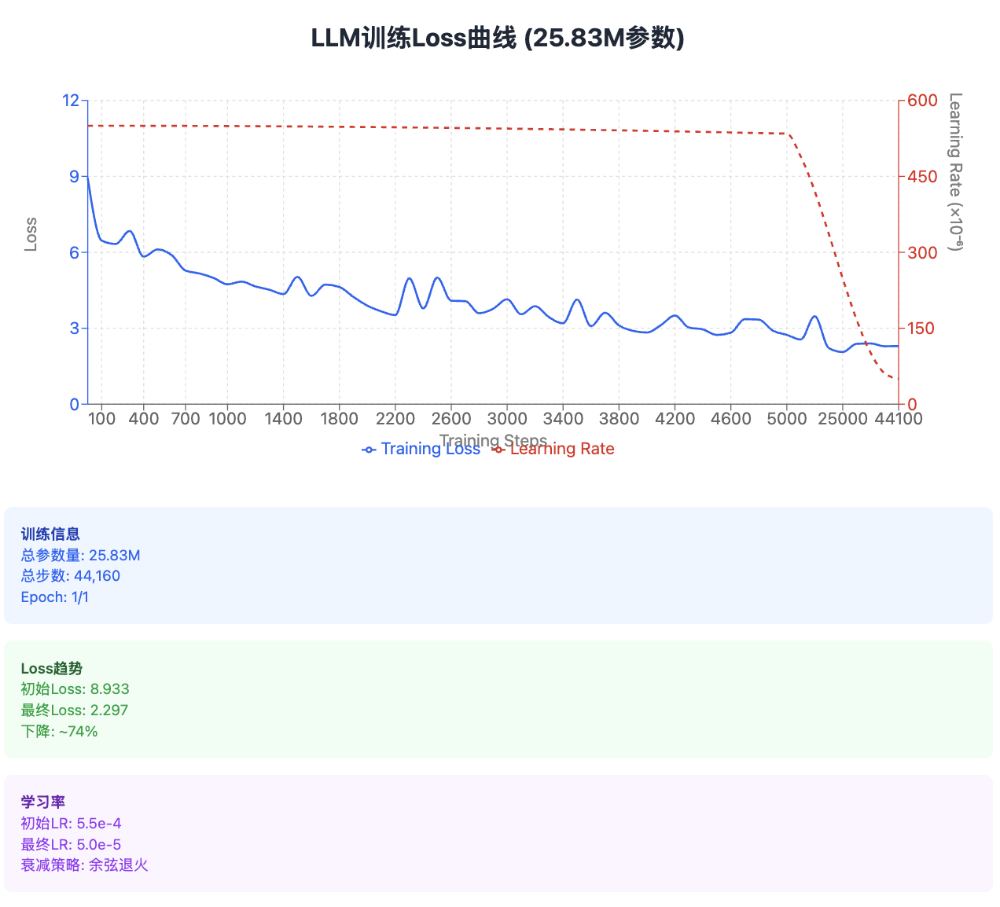

## 代码讲解

### 1.数据集Dataset

https://www.modelscope.cn/datasets/deepctrl/deepctrl-sft-data

##### 我们要从匠数大模型的数据集中提取中文部分，清洗后筛掉超过 512 字的文本片段，最终拼接成一份约 1.6GB 的高质量预训练语料，输出为 pretrain_hq.jsonl 文件，供模型使用。

##### 数据集如下：
{"text": "<|im_start|>我知道底边长度和高，分别是5cm和8cm，请告诉我计算出来的面积是多少。三角形的面积为20平方厘米。<|im_end|> <|im_start|>为什么理智告诉我们不要跟陌生人接触？因为陌生人可能会对我们的个人安全造成威胁、危害或诱骗等恶劣行为。<|im_end|> <|im_start|>上一次科比在NBA总决赛中获得总冠军是哪一年？科比在NBA总决赛中最后一次获得总冠军是在2010年。<|im_end|> <|im_start|>写一首五言诗，以“秋天”为主题。秋叶飘飘降，秋风肆虐长街，落叶纷纷掉下，百鸟南飞不归，唯有寒蝉孤嘶。<|im_end|> <|im_start|>好的。那你可以跟我聊一下最近的天气吗？当然可以。最近的天气因地区而异，你想知道哪个城市的天气情况呢？<|im_end|> <|im_start|>好的，那么请你接着把这个句子进一步改写，加入一个介绍该书的短语。这本畅销书是由名著名文学家所著写的。<|im_end|> <|im_start|>从以下描述中归纳出这是哪种动物：该动物四肢行走，有毛发，是哺乳动物。这是哺乳动物，具体种类无法确定。<|im_end|> <|im_start|>请问这周末的天气怎么样？我需要您告诉我您所在的城市地区，我可以通过查询天气API来提供相关天气信息。<|im_end|>"}

##### 这个数据集来自以下数据集的整合
- BelleGroup/train_3.5M_CN
- LinkSoul/instruction_merge_set
- stingning/ultrachat
- BAAI/COIG-PC-core
- shibing624/sharegpt_gpt4
- shareAI/ShareGPT-Chinese-English-90k
- Tiger Research
- BelleGroup/school_math_0.25M
- YeungNLP/moss-003-sft-data

### 2.分词器Tokenizer

在自然语言处理中，分词器的作用是将文本中的单词或字符转换成模型能理解的数字编号。你可以把这个过程想象成使用一本词典：每个词都会被映射到一个唯一的编号，就像查词典时找到它在“第几页”一样。例如，“hello”可能对应编号 36，而“world”是 872。

在实际工程中，我们通常会选择使用开源社区提供的高质量分词器（如 GPT、qwen等的分词器）。这类“标准词典”的优点是压缩率高——能用尽可能少的 token 编码尽可能多的信息。但它们的缺点也很明显：词表动辄包含数十万甚至上百万条词条，模型体积因此显著增加。

相比之下，自定义训练的分词器可以根据具体任务灵活设计词表大小和内容，甚至压缩到只有几千或几万个 token。不过它们的压缩率通常较低，例如可能会把 "hello" 拆成 "h e l l o" 五个 token，造成冗长输入，同时难以覆盖生僻词。

分词器的选择对模型性能和体积有直接影响，尤其是对轻量模型（如 MiniMind）来说更是关键。如果词表太大，模型的嵌入层（Embedding）参数占比会过高，导致“头重脚轻”；因此，我们倾向于将词表控制得尽可能小，以节省参数量和加速推理。

> 需要注意的是，本课程第 2-3 周已系统讲解了如何训练自定义分词器，包括语料准备、BPE算法实现与词表控制策略，此处不再赘述。如需回顾，请参考Ween2 /3。



### 3.模型结构

#### 模型结构可视化

- 8层隐藏层
- 512维隐藏状态
- 8个注意力头
- 2个key-value头（GQA）

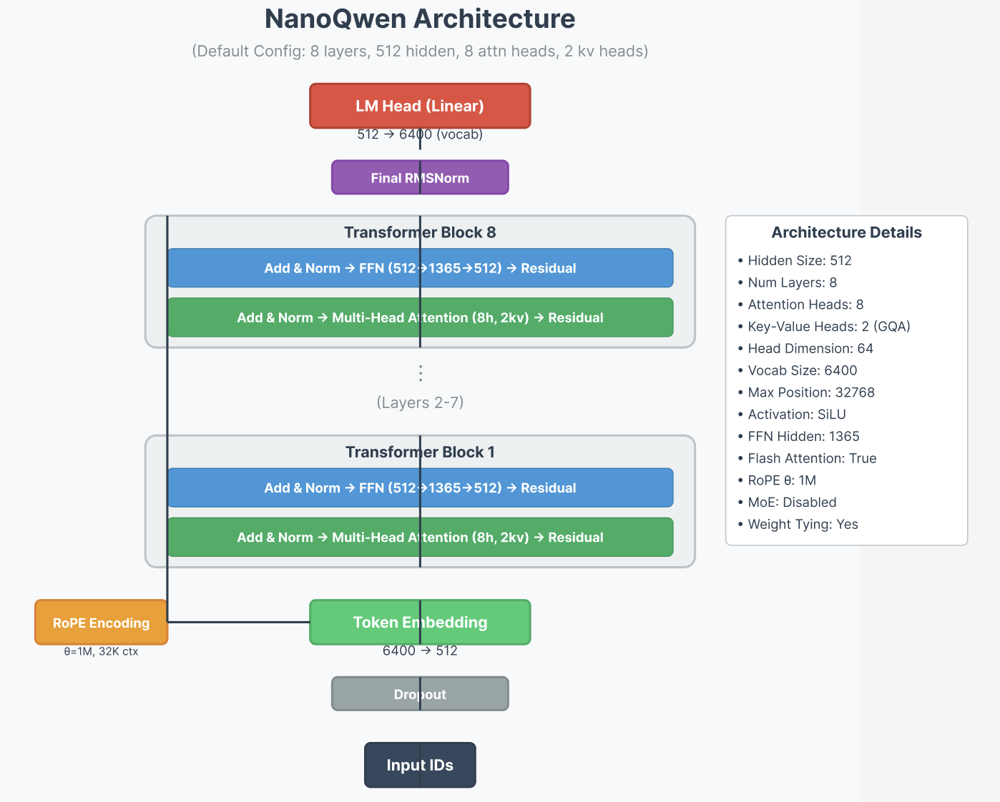

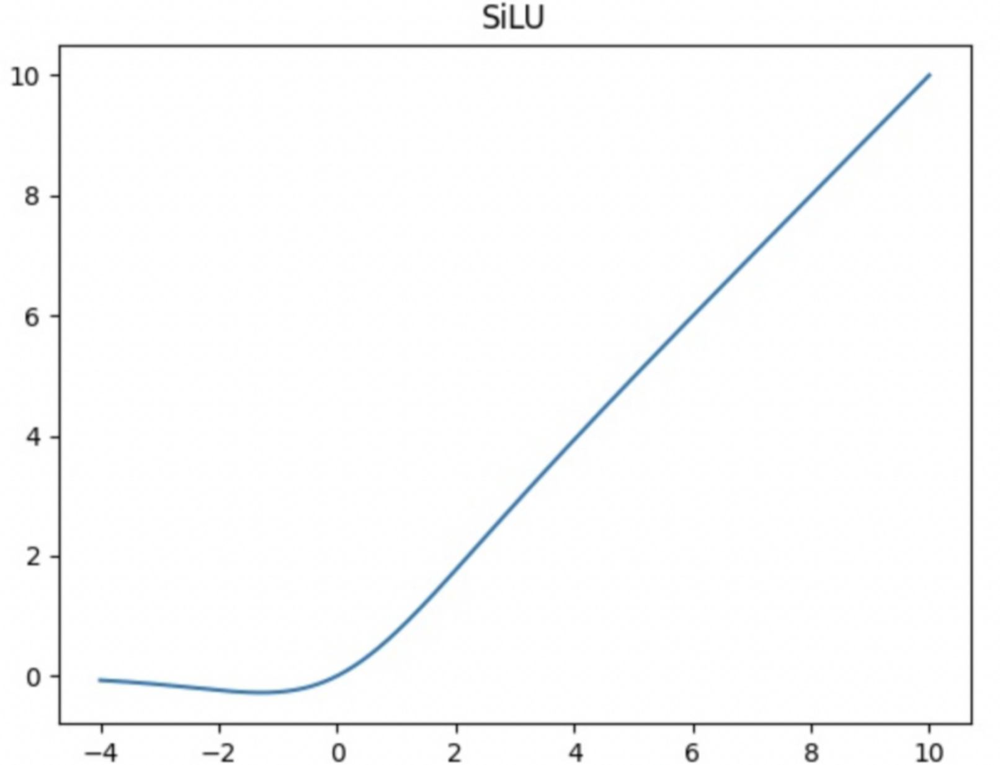

#### 📘 NanoQwen 模型代码详解

本文档将详细解析 `NanoQwen` 的模型代码，该代码实现了一个轻量级的、类似 Qwen 的 Transformer 模型，并支持混合专家（Mixture of Experts, MoE）架构。

代码主要分为三个部分：
1.  **`NanoQwenConfig`**: 模型的配置文件类。
2.  **`NanoQwen Model`**: 模型的核心组件，包括注意力机制、前馈网络、MoE 模块和 Transformer 层。
3.  **`NanoQwenForCausalLM`**: 完整的因果语言模型，包含模型主体和语言模型头。

---

##### 1. `NanoQwenConfig` - 模型配置

这是模型的配置类，继承自 `transformers.PretrainedConfig`。它用于定义模型的所有超参数，方便模型的保存、加载和复用。

```python
# 📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘
#                                             NanoQwen Config
# 📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘📘

from transformers import PretrainedConfig


class NanoQwenConfig(PretrainedConfig):
    model_type = "nanoqwen"

    def __init__(
            self,
            dropout: float = 0.0,
            bos_token_id: int = 1,
            eos_token_id: int = 2,
            hidden_act: str = 'silu',
            hidden_size: int = 512,
            intermediate_size: int = None,
            max_position_embeddings: int = 32768,
            num_attention_heads: int = 8,
            num_hidden_layers: int = 8,
            num_key_value_heads: int = 2,
            vocab_size: int = 6400,
            rms_norm_eps: float = 1e-05,
            rope_theta: int = 1000000.0,
            flash_attn: bool = True,
            ####################################################
            # Here are the specific configurations of MOE
            # When use_moe is false, the following is invalid
            ####################################################
            use_moe: bool = False,
            num_experts_per_tok: int = 2,
            n_routed_experts: int = 4,
            n_shared_experts: int = 1,
            scoring_func: str = 'softmax',
            aux_loss_alpha: float = 0.1,
            seq_aux: bool = True,
            norm_topk_prob: bool = True,
            **kwargs
    ):
        super().__init__(**kwargs)
        self.dropout = dropout
        self.bos_token_id = bos_token_id
        self.eos_token_id = eos_token_id
        self.hidden_act = hidden_act
        self.hidden_size = hidden_size
        self.intermediate_size = intermediate_size
        self.max_position_embeddings = max_position_embeddings
        self.num_attention_heads = num_attention_heads
        self.num_hidden_layers = num_hidden_layers
        self.num_key_value_heads = num_key_value_heads
        self.vocab_size = vocab_size
        self.rms_norm_eps = rms_norm_eps
        self.rope_theta = rope_theta
        self.flash_attn = flash_attn

```

###### 详细解释

###### **通用配置**
*   `model_type`: 模型类型标识，固定为 "nanoqwen"。
*   `dropout`: 在全连接层和注意力层中使用的 dropout 概率。
*   `bos_token_id`, `eos_token_id`: 句子开始和结束标记的 ID。
*   `hidden_act`: 激活函数类型，这里使用 `silu` (Sigmoid-weighted Linear Unit)，也被称为 Swish。
*   `hidden_size`: 模型隐藏层的大小（维度）。
*   `intermediate_size`: 前馈网络（FFN）中间层的大小。如果为 `None`，会根据 `hidden_size` 自动计算。
*   `max_position_embeddings`: 模型能处理的最大序列长度。
*   `num_attention_heads`: 注意力头的数量。
*   `num_hidden_layers`: Transformer 层的总数。
*   `num_key_value_heads`: Key 和 Value 注意力头的数量。这用于实现分组查询注意力（Grouped-Query Attention, GQA）。当 `num_key_value_heads < num_attention_heads` 时，多个 Query 头会共享同一组 Key 和 Value 头，以减少计算量和内存占用。
*   `vocab_size`: 词汇表大小。
*   `rms_norm_eps`: RMSNorm 归一化层中为防止除以零而添加的小数。
*   `rope_theta`: 旋转位置编码（RoPE）的 `theta` 基数。
*   `flash_attn`: 是否使用 Flash Attention 优化。Flash Attention 是一种高效的注意力实现，需要 PyTorch 2.0 或更高版本。

---

###### 2. `NanoQwen Model` - 模型核心组件

这部分包含了模型的所有构建模块。



###### `RMSNorm`

RMSNorm（Root Mean Square Layer Normalization）的公式如下：

给定输入向量 $x \in \mathbb{R}^d$，RMSNorm 的计算方式是：

$$
\text{RMSNorm}(x) = \frac{x}{\text{RMS}(x)} \cdot \gamma
$$

其中：

$$
\text{RMS}(x) = \sqrt{\frac{1}{d} \sum_{i=1}^{d} x_i^2 + \epsilon}
$$

* $\gamma \in \mathbb{R}^d$：是可学习的缩放参数（类似 LayerNorm 中的 scale）
* $\epsilon$：是一个很小的常数，用于防止除以 0（数值稳定性）
* **没有 bias 项**（不同于 LayerNorm）

---

##### 🔁 与 LayerNorm 的区别

* **LayerNorm** 是对每个样本的所有特征维度做 **均值+方差归一化**：

  $$
  \text{LayerNorm}(x) = \frac{x - \mu}{\sigma} \cdot \gamma + \beta
  $$
* **RMSNorm** 是只归一化**平方和的均值（RMS）**，即：

  * **不减均值**
  * 更加轻量，效果接近甚至更好（尤其在大模型中）


这是一种层归一化的变体，由 Llama 等模型推广。与标准的 `LayerNorm` 相比，它只对输入的均方根进行归一化，而没有减去均值，因此计算上更高效。

```python
class RMSNorm(torch.nn.Module):
    def __init__(self, dim: int, eps: float = 1e-5):
        super().__init__()
        self.eps = eps
        # 尽管起始是 1，但它是 nn.Parameter，训练过程中会按需求自由学习到不同维度的最佳缩放值。
        self.weight = nn.Parameter(torch.ones(dim))

    def _norm(self, x):
        # 计算输入的均方根的倒数，并乘以输入
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)

    def forward(self, x):
        # 归一化后，乘以可学习的缩放参数 weight
        return self.weight * self._norm(x.float()).type_as(x)
```
- **`_norm(self, x)`**: 核心计算逻辑，`rsqrt` 是平方根倒数函数。
- **`forward(self, x)`**: 将归一化后的张量乘以一个可学习的 `weight` 参数，用于缩放每个维度的值。

###### 旋转位置编码 (RoPE) 辅助函数

RoPE 是一种将位置信息融入注意力机制的有效方法，它通过旋转 Query 和 Key 的嵌入向量来实现。

```python
def precompute_freqs_cis(dim: int, end: int = int(32 * 1024), theta: float = 1e6):
    # 1. 计算频率 freqs
    freqs = 1.0 / (theta ** (torch.arange(0, dim, 2)[: (dim // 2)].float() / dim))
    # 2. 创建位置序列 t
    t = torch.arange(end, device=freqs.device)
    # 3. 计算每个位置和每个频率的外积，得到角度
    freqs = torch.outer(t, freqs).float()
    # 4. 计算余弦和正弦值
    freqs_cos = torch.cat([torch.cos(freqs), torch.cos(freqs)], dim=-1)
    freqs_sin = torch.cat([torch.sin(freqs), torch.sin(freqs)], dim=-1)
    return freqs_cos, freqs_sin

def apply_rotary_pos_emb(q, k, cos, sin, position_ids=None, unsqueeze_dim=1):
    def rotate_half(x):
        # 将向量的后半部分移到前面，并取反；前半部分移到后面
        return torch.cat((-x[..., x.shape[-1] // 2:], x[..., : x.shape[-1] // 2]), dim=-1)

    # 应用旋转变换
    q_embed = (q * cos.unsqueeze(unsqueeze_dim)) + (rotate_half(q) * sin.unsqueeze(unsqueeze_dim))
    k_embed = (k * cos.unsqueeze(unsqueeze_dim)) + (rotate_half(k) * sin.unsqueeze(unsqueeze_dim))
    return q_embed, k_embed
```
- **`precompute_freqs_cis`**: 预先计算好所有可能位置的 RoPE 旋转矩阵（由 `cos` 和 `sin` 值表示），避免在每次前向传播时重复计算。
- **`apply_rotary_pos_emb`**: 将预计算好的 `cos` 和 `sin` 值应用到 Query 和 Key 向量上，实现旋转。

###### `Attention`

实现了分组查询注意力（GQA）机制，并集成了 RoPE 和 Flash Attention。

```python
# ... (repeat_kv function) ...
class Attention(nn.Module):
    # ... (__init__ method) ...
    def forward(self,
                x: torch.Tensor,
                position_embeddings: Tuple[torch.Tensor, torch.Tensor],
                past_key_value: Optional[Tuple[torch.Tensor, torch.Tensor]] = None,
                use_cache=False,
                attention_mask: Optional[torch.Tensor] = None):
        bsz, seq_len, _ = x.shape
        # 1. 线性投影得到 Q, K, V
        xq, xk, xv = self.q_proj(x), self.k_proj(x), self.v_proj(x)
        # 2. 重塑为多头形式
        xq = xq.view(bsz, seq_len, self.n_local_heads, self.head_dim)
        xk = xk.view(bsz, seq_len, self.n_local_kv_heads, self.head_dim)
        xv = xv.view(bsz, seq_len, self.n_local_kv_heads, self.head_dim)

        # 3. 应用 RoPE
        cos, sin = position_embeddings
        xq, xk = apply_rotary_pos_emb(xq, xk, cos[:seq_len], sin[:seq_len])

        # 4. KV 缓存机制，用于推理加速
        if past_key_value is not None:
            xk = torch.cat([past_key_value[0], xk], dim=1)
            xv = torch.cat([past_key_value[1], xv], dim=1)
        past_kv = (xk, xv) if use_cache else None

        # 5. GQA: 重复 K, V 头以匹配 Q 头数量
        xk = repeat_kv(xk, self.n_rep)
        xv = repeat_kv(xv, self.n_rep)
        
        # 6. 交换维度以进行注意力计算
        xq, xk, xv = xq.transpose(1, 2), xk.transpose(1, 2), xv.transpose(1, 2)

        # 7. 选择性使用 Flash Attention 或标准注意力
        if self.flash and seq_len != 1:
            # 使用 Flash Attention (高效)
            output = F.scaled_dot_product_attention(xq, xk, xv, attn_mask=..., dropout_p=..., is_causal=True)
        else:
            # 标准的点积注意力
            scores = (xq @ xk.transpose(-2, -1)) / math.sqrt(self.head_dim)
            # 添加因果掩码
            scores = scores + torch.triu(...)
            # 添加 padding 掩码
            if attention_mask is not None:
                scores = scores + extended_attention_mask
            scores = F.softmax(scores.float(), dim=-1).type_as(xq)
            scores = self.attn_dropout(scores)
            output = scores @ xv

        # 8. 恢复形状并进行输出投影
        output = output.transpose(1, 2).reshape(bsz, seq_len, -1)
        output = self.resid_dropout(self.o_proj(output))
        return output, past_kv
```
- **`repeat_kv`**: 一个辅助函数，用于 GQA。它将 K 和 V 的头在特定维度上重复 `n_rep` 次，使其数量与 Q 的头数量相匹配。
- **`forward`**:
    1.  通过线性层将输入 `x` 投影为 `xq`, `xk`, `xv`。
    2.  应用 RoPE 注入位置信息。
    3.  处理 KV 缓存，这在自回归生成（推理）时至关重要，可以避免重复计算过去的键值。
    4.  使用 `repeat_kv` 实现 GQA。
    5.  根据配置和 PyTorch 版本，选择使用 `F.scaled_dot_product_attention` (Flash Attention) 或手动实现标准注意力。Flash Attention 在硬件支持的情况下能显著提升速度和减少内存占用。
    6.  最后，将注意力输出通过一个线性层 `o_proj` 投影回 `hidden_size`。

###### `FeedForward`

标准的 Transformer 前馈网络，但使用了 SwiGLU 激活函数，这在现代 LLM 中很常见，能提供比 ReLU 更好的性能。

```python
class FeedForward(nn.Module):
    def __init__(self, config: NanoQwenConfig):
        super().__init__()
        # ... 自动计算 intermediate_size ...
        self.gate_proj = nn.Linear(config.hidden_size, config.intermediate_size, bias=False)
        self.down_proj = nn.Linear(config.intermediate_size, config.hidden_size, bias=False)
        self.up_proj = nn.Linear(config.hidden_size, config.intermediate_size, bias=False)
        self.dropout = nn.Dropout(config.dropout)
        self.act_fn = ACT2FN[config.hidden_act]

    def forward(self, x):
        # SwiGLU: silu(gate_proj(x)) * up_proj(x)
        return self.dropout(self.down_proj(self.act_fn(self.gate_proj(x)) * self.up_proj(x)))
```
- **`forward`**: 计算 `act_fn(gate_proj(x)) * up_proj(x)`。这种结构包含一个门控机制（`up_proj` 的输出），可以动态地调节 `gate_proj` 的输出，从而增强了模型的表达能力。


 

```python
class NanoQwenModel(nn.Module):
    def __init__(self, config: NanoQwenConfig):
        super().__init__()
        # ...
        self.embed_tokens = nn.Embedding(...)
        self.layers = nn.ModuleList([NanoQwenBlock(...) for l in range(config.num_hidden_layers)])
        self.norm = RMSNorm(...)
        
        # 预计算 RoPE 的 sin/cos 值
        freqs_cos, freqs_sin = precompute_freqs_cis(...)
        self.register_buffer("freqs_cos", freqs_cos, persistent=False)
        self.register_buffer("freqs_sin", freqs_sin, persistent=False)

    def forward(self, input_ids, ...):
        # 1. 获取词嵌入
        hidden_states = self.dropout(self.embed_tokens(input_ids))
        # 2. 获取当前位置的 RoPE 编码
        position_embeddings = (self.freqs_cos[...], self.freqs_sin[...])
        # 3. 依次通过所有 Transformer 层
        presents = []
        for layer in self.layers:
            hidden_states, present = layer(hidden_states, position_embeddings, ...)
            presents.append(present)
        # 4. 最后一次归一化
        hidden_states = self.norm(hidden_states)
        # 5. 收集所有 MoE 层的辅助损失
        aux_loss = sum(layer.mlp.aux_loss for layer in self.layers if isinstance(layer.mlp, MOEFeedForward))
        return hidden_states, presents, aux_loss
```
- **`__init__`**:
    - 创建词嵌入层 `embed_tokens`。
    - 创建一个包含 `num_hidden_layers` 个 `NanoQwenBlock` 的列表。
    - 创建最终的 `RMSNorm` 层。
    - 调用 `precompute_freqs_cis` 预计算 RoPE 的旋转矩阵，并使用 `register_buffer` 将它们注册为模型的缓冲区（它们会随模型移动到 GPU/CPU，但不是可训练的参数）。
- **`forward`**:
    1.  将输入的 `input_ids` 转换为词嵌入。
    2.  根据当前序列的位置，从预计算的缓冲区中提取相应的 RoPE 编码。
    3.  将数据依次传入每个 `NanoQwenBlock`。
    4.  在所有层之后进行最后一次归一化。
    5.  如果使用了 MoE，汇总所有 MoE 层的辅助损失。

---

##### 3. `NanoQwenForCausalLM` - 因果语言模型

这是最终的模型类，它在 `NanoQwenModel` 的基础上增加了一个用于预测下一个词的“语言模型头”（LM Head），并集成了 `transformers` 库的生成功能。

```python
class NanoQwenForCausalLM(PreTrainedModel, GenerationMixin):
    config_class = NanoQwenConfig

    def __init__(self, config: NanoQwenConfig = None):
        # ...
        super().__init__(self.config)
        self.model = NanoQwenModel(self.config)
        # 语言模型头，一个线性层
        self.lm_head = nn.Linear(self.config.hidden_size, self.config.vocab_size, bias=False)
        # 权重绑定：词嵌入和 LM Head 共享权重
        self.model.embed_tokens.weight = self.lm_head.weight
        self.OUT = CausalLMOutputWithPast()

    def forward(self, input_ids, ...):
        # 1. 调用模型主体
        h, past_kvs, aux_loss = self.model(...)
        # 2. 将隐藏状态通过 LM Head 转换为 logits
        logits = self.lm_head(h[:, slice_indices, :])
        # 3. 将所有输出封装到标准输出对象中
        self.OUT.__setitem__('logits', logits)
        self.OUT.__setitem__('aux_loss', aux_loss)
        self.OUT.__setitem__('past_key_values', past_kvs)
        return self.OUT
```
- **`__init__`**:
    - 实例化 `NanoQwenModel` 作为模型主体。
    - 创建一个线性层 `lm_head`，它将 `hidden_size` 的隐藏状态映射到 `vocab_size` 大小的 logits 分布。
    - **权重绑定** (`self.model.embed_tokens.weight = self.lm_head.weight`): 这是一个重要的技巧。它让输入词嵌入矩阵和输出的 LM Head 共享同一组权重。这不仅能显著减少模型参数量，还能提高模型性能，因为模型学习到了 token 和其在输出空间中的表示之间更直接的联系。
- **`forward`**:
    - 调用 `self.model` 得到最后一层的隐藏状态 `h`、KV 缓存 `past_kvs` 和辅助损失 `aux_loss`。
    - 将隐藏状态 `h` 输入 `self.lm_head` 得到 `logits`。
    - 将 `logits`、`aux_loss` 和 `past_key_values` 等结果打包成一个 `CausalLMOutputWithPast` 对象返回。这种标准化的输出格式与 `transformers` 库的 `generate()` 方法和其他功能无缝兼容。

### 4. 训练

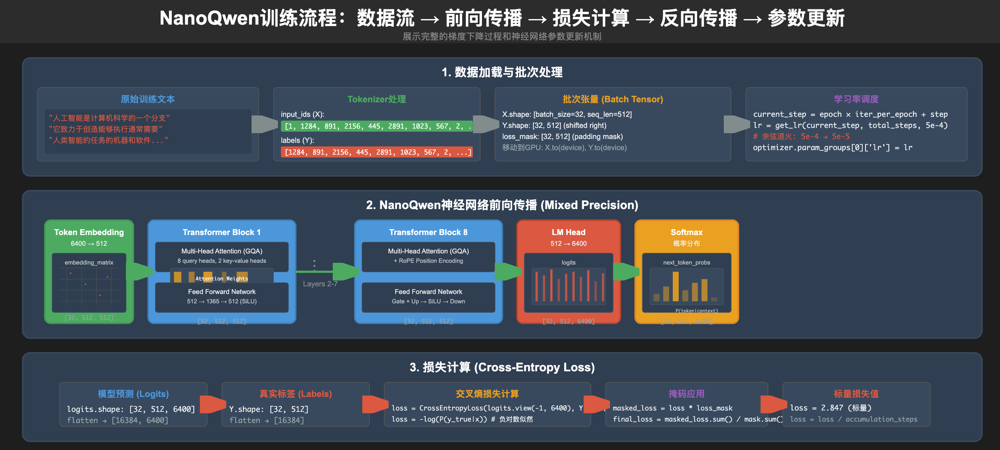

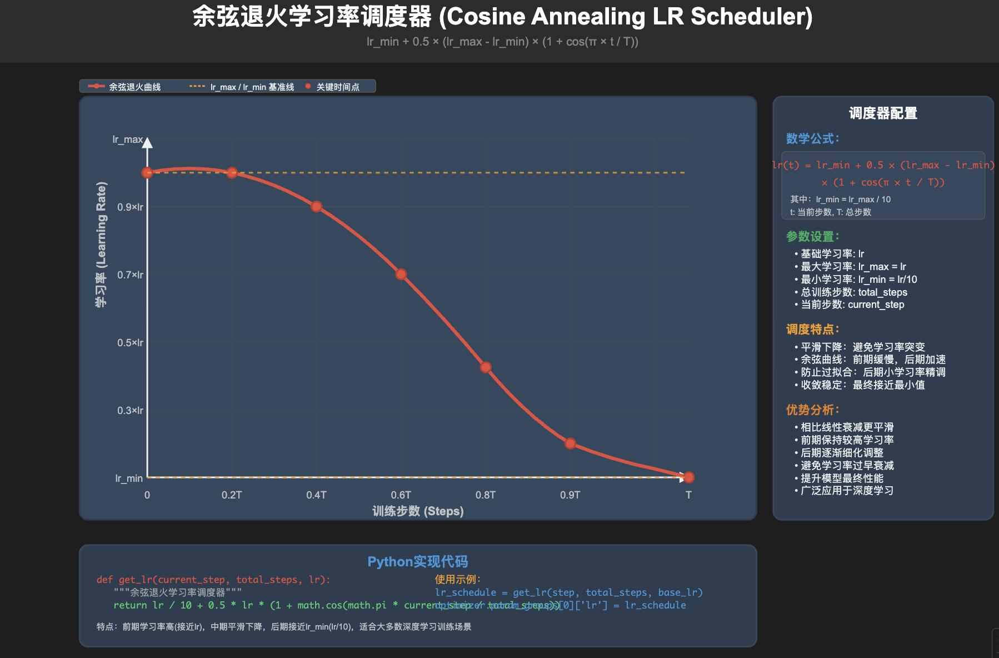